<a href="https://colab.research.google.com/github/muhammad-usman-tech/hr-employee-attrition-analysis/blob/main/HR_attrition_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   age                       1470 non-null   int64 
 1   attrition                 1470 non-null   object
 2   businesstravel            1470 non-null   object
 3   dailyrate                 1470 non-null   int64 
 4   department                1470 non-null   object
 5   distancefromhome          1470 non-null   int64 
 6   education                 1470 non-null   int64 
 7   educationfield            1470 non-null   object
 8   employeecount             1470 non-null   int64 
 9   employeenumber            1470 non-null   int64 
 10  environmentsatisfaction   1470 non-null   int64 
 11  gender                    1470 non-null   object
 12  hourlyrate                1470 non-null   int64 
 13  jobinvolvement            1470 non-null   int64 
 14  joblevel                

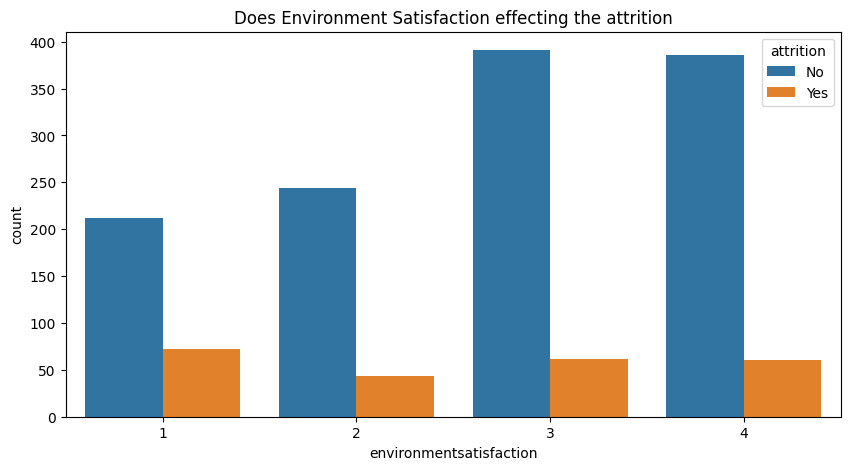

,max_salary,min_salary,avg_salary
department,,,
Human Resources,19717,1555,6654.507937
Research Development,19999,1009,6281.252862
Sales,19847,1052,6959.172646


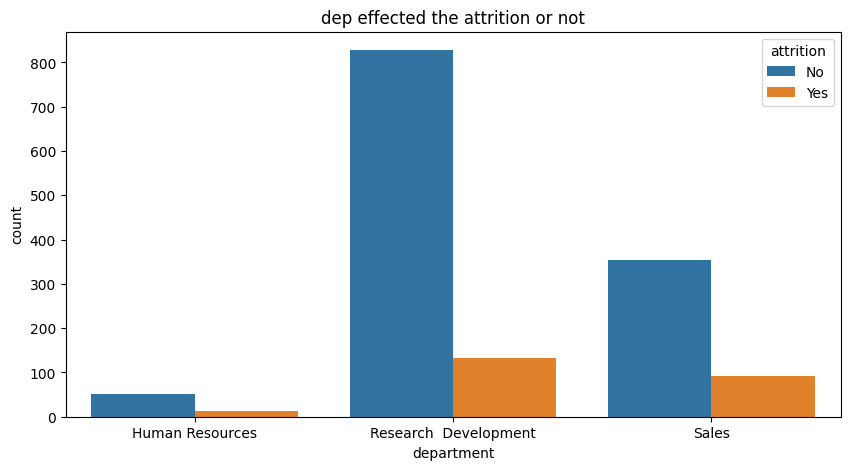

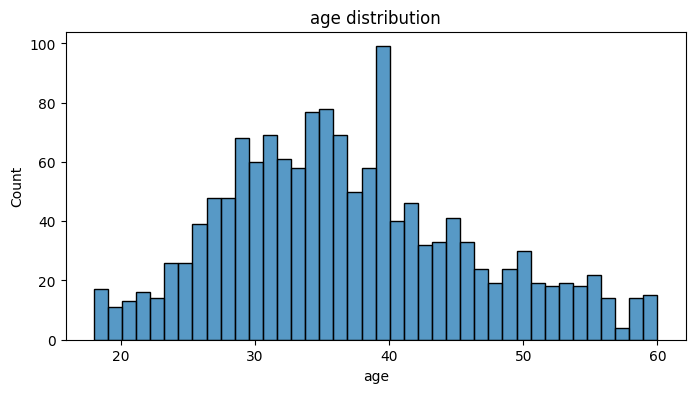

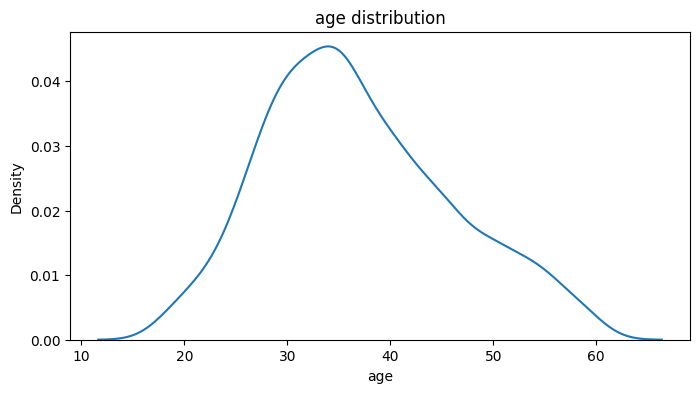

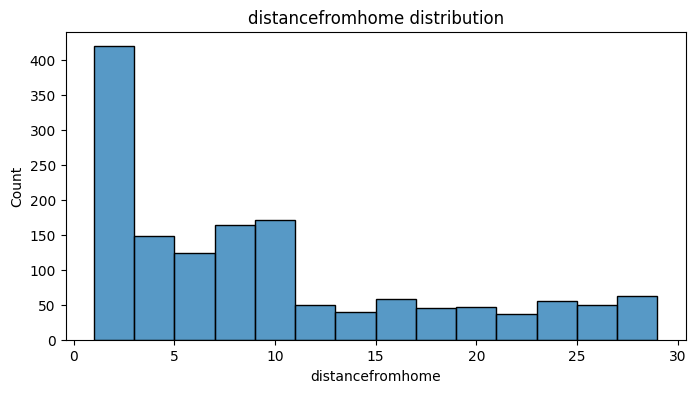

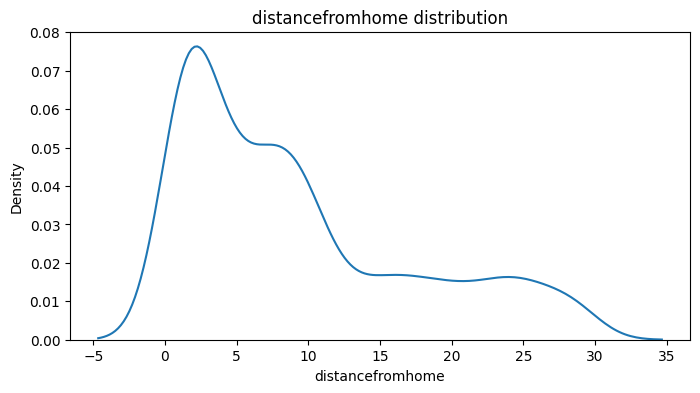

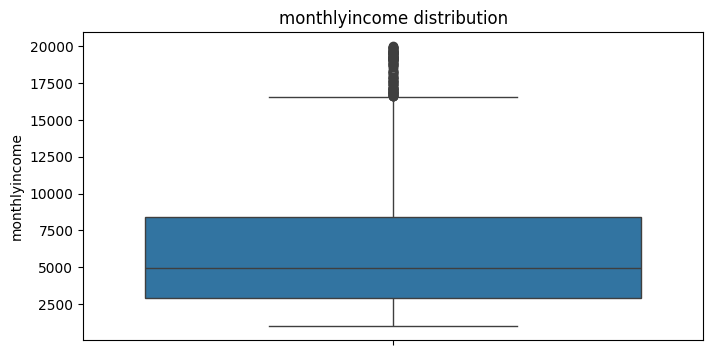

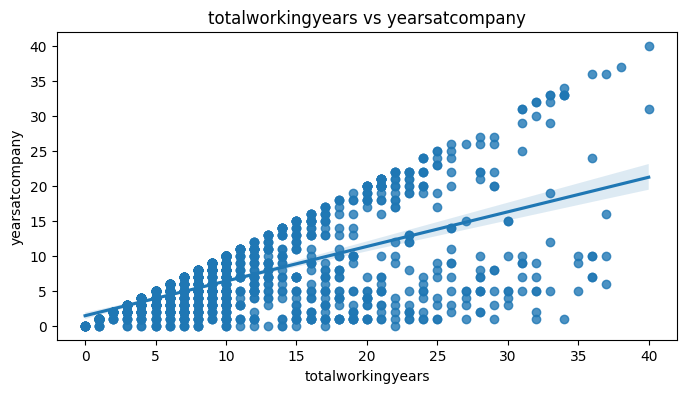

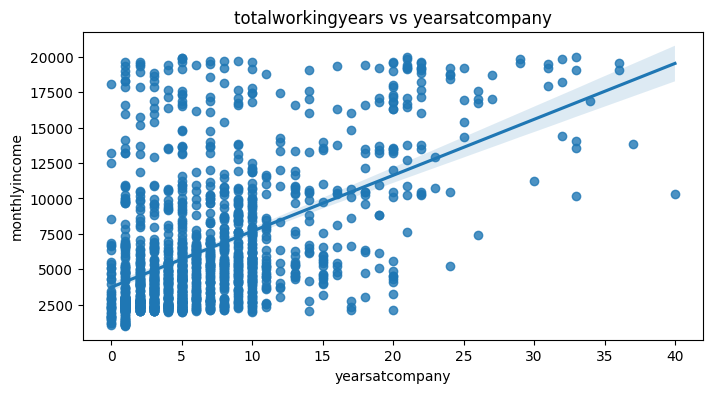

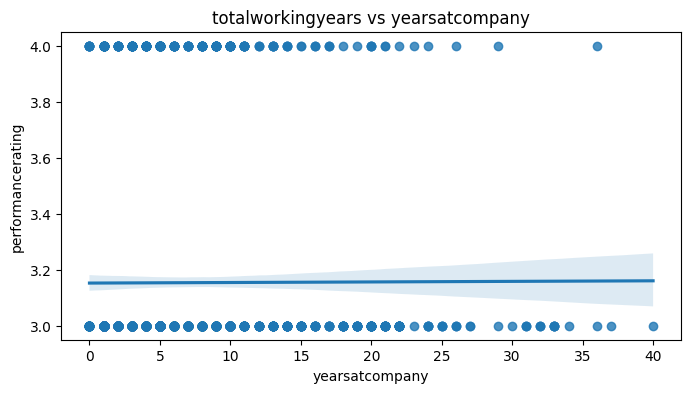

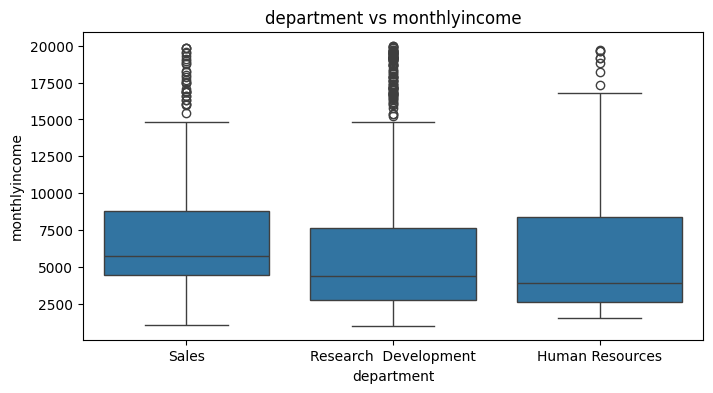

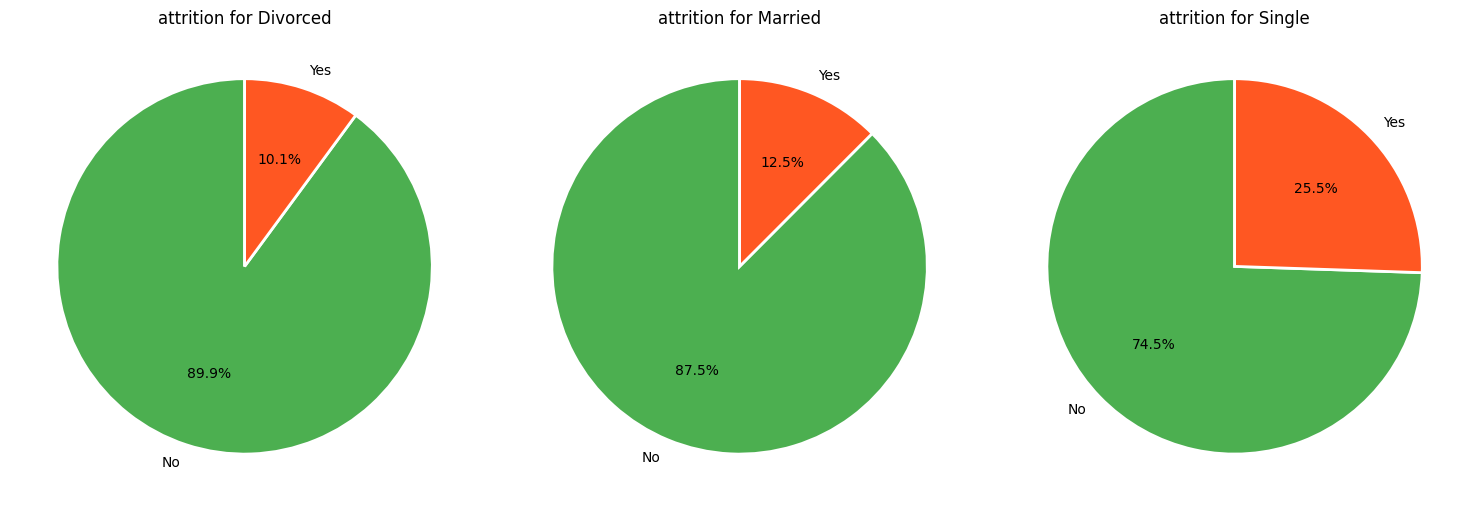

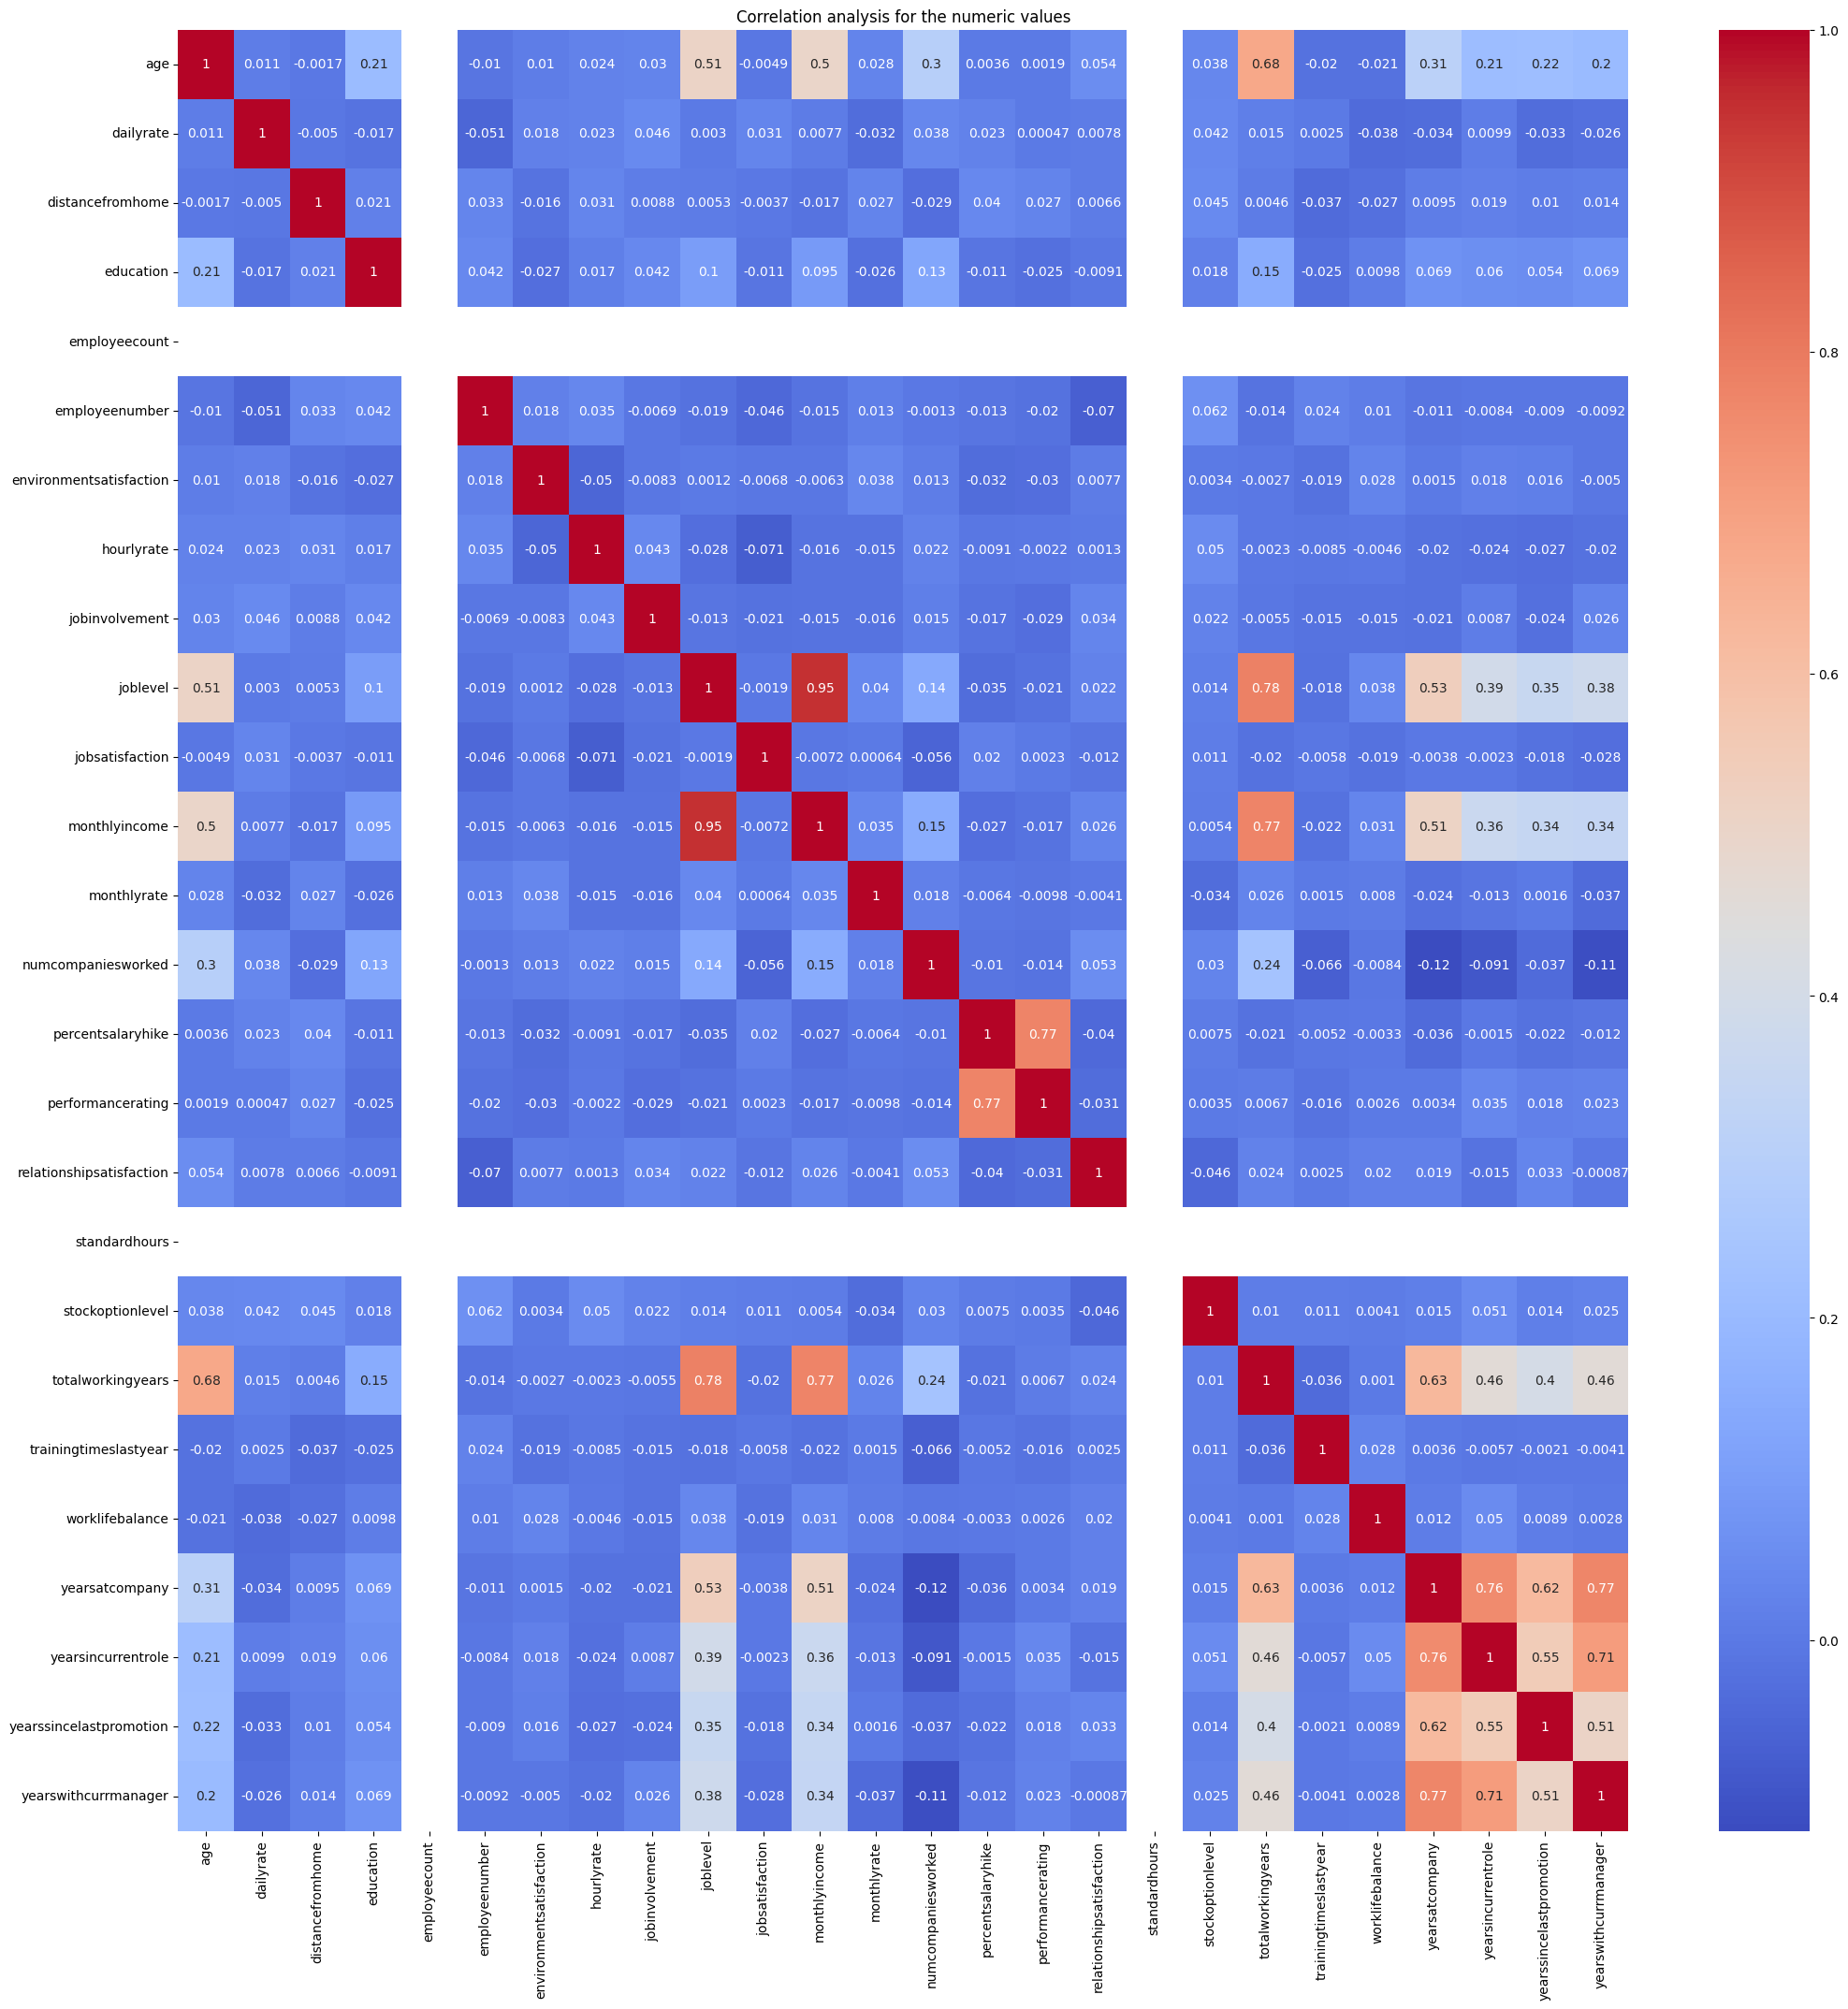

orignal shape: 1470
cleaned data shape : 114
length of the outliers: 1356


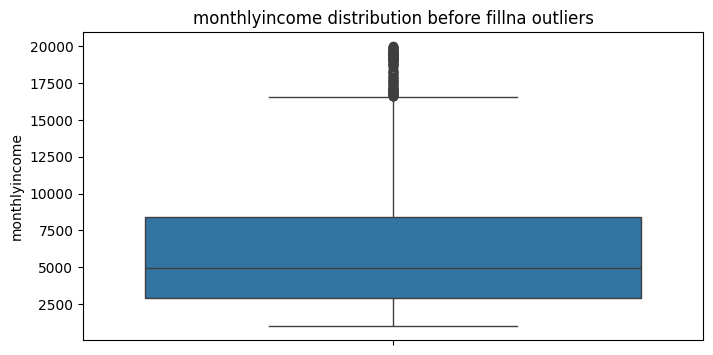

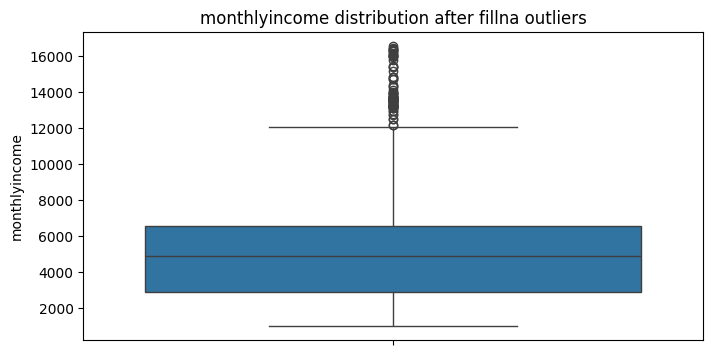

,,count
education,attrition,
5,Yes,5
1,Yes,31
5,No,43
2,Yes,44
4,Yes,58
3,Yes,99
1,No,139
2,No,238
4,No,340


In [17]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# importing data
df=pd.read_csv('/content/WA_Fn-UseC_-HR-Employee-Attrition.csv')

# inspecting the data
pd.set_option('display.max_columns', None)
pd.set_option('display.max_info_columns', 100)
# df.info()
df.head()
df.tail()

df.shape #(1470,35) total 35 attributes and 1470 rows these are not much like we had previous 5 lac row's

# now we can do some of the ETL=means cleaning

df.isnull().sum() #got 0 nulls

df.duplicated().sum() # got 0 duplicates

df.columns=df.columns.str.strip()
df.columns=df.columns.str.lower()
df.info()

obj_columns=df.select_dtypes(include=['object'])
for col in obj_columns:
  df[col]=df[col].str.strip()

df.columns=df.columns.str.replace(r'(?<!^)(?=[A-Z])', '_', regex=True).str.lower()


for col in obj_columns:
  df[col]=df[col].str.replace(r'[^a-zA-Z0-9\s]','',regex=True)


# if we will talk about the data types so almost all the data types are correct logically yeh these are some categories or some bool in the data types that are in the obj but that doest not make any issue and
# yeh some values or data of the columns are from 0 or 1 or 2 or 3 and it can be go with categorical but these are in the int and that is also ok it does not make any issue because we can do the aggregating and groupby and many things on that

# example: df.groupby('education')['gender'].value_counts() here the education holds the data of the 1,2,3,4,5 and it was integar

df['gender'].unique() #array([' emale', ' ale'], dtype=object)
df['gender']=df['gender'].replace({' ale':'male',' emale':'female'})
df['gender'].unique() #done and i just notices this when i was executing the example i notices these ale instead od male in the gender then caught an random thing
# i have done the basic cleaning that is required here i think


# Starting the EDA With the univariate analysis(and making the questions or findings after viewing the attributes)
# (using the graphs that uses 2 attributes atleast)

# just got random think on environmentsatisfaction
satisfy=df.groupby('environmentsatisfaction')['attrition'].value_counts().reset_index(name='count')

plt.figure(figsize=(10,5))
sns.barplot(data=satisfy, x='environmentsatisfaction', y='count', hue='attrition')
plt.title('Does Environment Satisfaction effecting the attrition')
plt.show()
# ok so the vertical line in the bins are further specifying the yes and no
# the the bottom of that black lines means yes and the upper top means the no
# so people with the satis-level 1 has left the most with 72 number but the interesting thing is people with the satisfaction level 4 are the seconh highest at the 62 in lefting company means we cant say people with level 1 are leaving and 4 are not leaving but th level 2 people are less at leaving with 42
# on the other hand we can see the least number of people with 212 are working in the company as compare to level 3 and 4 which have 392 and 386 people with no attrition that makes sense


# second barchart:

# department with monthly income affecting the attrition or attrition rate or the count by the department

# Apply aggregation on the groupby object directly
income_by_dept = df.groupby('department').agg(
    max_salary=('monthlyincome', 'max'),
    min_salary=('monthlyincome', 'min'),
    avg_salary=('monthlyincome', 'mean')
)

display(income_by_dept)
# 	max_salary	min_salary	avg_salary
# department
# sales	19847	1052	6959.172646
# research & Development	19999	1009	6281.252862
# human Resources	19717	1555	6654.507937
# all these values are almost almost equal among all the departments so we can just check the attrition rate by the department




dep=df.groupby('department')['attrition'].value_counts().reset_index(name='count')

plt.figure(figsize=(10,5))
sns.barplot(data=dep, x='department', y='count', hue='attrition')
plt.title('dep effected the attrition or not')
plt.show()
#INSIGHTS: in the hr department (althought he salary is almost same like min max and avg ) the max salary was the minimum and the minimum salary was the maximum and only less people attrition(yes) left the company
# while on the other hand resaech dep has maximum salary is maximum and the minimum salary is minimum is afected by the attrition most 133 people left it
# but one more thing most 828 emp re working in the rsearch department

# ok now move towards next things histogram that are ue to display the frequency distribution of quantative data or numeric data

# ok so firstly we can go for the age nd the distancefrom home
plt.figure(figsize=(8,4))
sns.histplot(data=df,x='age',bins=40)
plt.title('age distribution')
plt.show()
df['age'].min()

plt.figure(figsize=(8,4))
sns.kdeplot(data=df,x='age')
plt.title('age distribution')
plt.show()

df['age'].max()

# after watching the kde and histplot it is observed that the people of less age like from 18 to 20 or 25 are less in numbers and people of ge 30 to 43 to 45 are maximum in amount and then after 45 to 60 people are less in numbers nd the kde is bell curved just little rigt side long flow that more people are in amount os snior age then the amount of people of ge 18 - 25 but still i have told you it was the 90 percent bell curved



# now for distancefromhome(it was not mentioned that if the distance was in the meteres or in the km so can assume it in the km)
plt.figure(figsize=(8,4))
sns.histplot(data=df,x='distancefromhome')
plt.title('distancefromhome distribution')
plt.show()

plt.figure(figsize=(8,4))
sns.kdeplot(data=df,x='distancefromhome')
plt.title('distancefromhome distribution')
plt.show()
# the min dis is 1 and the max is 29 and it is observed that the distance 1-12 are much in amount and there are some few people who are from distance 12-29 but they exists
# and the kde was the left curved not the bell or right curved

df['distancefromhome'].min()
df['distancefromhome'].max()


# now making the box plot's by using single variable or attribute
# ok so using the monthly salary
plt.figure(figsize=(8,4))
sns.boxplot(data=df,y='monthlyincome')
plt.title('monthlyincome distribution')
plt.show()
# ok so in the box plot the min salary is 1000 and some thing and the max is 17500 and outliers are starting from this point and ending up at the 19900 or some thing


# now its time for the bivariate analysis and starting with the scatter plot

plt.figure(figsize=(8,4))
sns.regplot(data=df,x='totalworkingyears',y='yearsatcompany')
plt.title('totalworkingyears vs yearsatcompany')
plt.show()
# yes it is increasing and i think it was the obvious thing so we can just take different columns with years at company
plt.figure(figsize=(8,4))
sns.regplot(data=df,x='yearsatcompany',y='monthlyincome')
plt.title('totalworkingyears vs yearsatcompany')
plt.show()
# it was also the common sense thinking and yes its increasing again changing the columns

plt.figure(figsize=(8,4))
sns.regplot(data=df,x='yearsatcompany',y='performancerating')
plt.title('totalworkingyears vs yearsatcompany')
plt.show()

# no these have 0 reltion with each other

# now comming to the boxplot

plt.figure(figsize=(8,4))
sns.boxplot(data=df,x='department',y='monthlyincome')
plt.title('department vs monthlyincome')
plt.show()
# insights: # in the hr dept the maximum salary is the maximum and the minimum salary is also maximum as across all the depts and hr dept has minimum outliers as compare to others and the minimum salary in all the boxes is almost same just  few mneyy difference and ll the median are little more close to the Q1 as ompare to  the Q3 and i dont know why and whwn this happen
# now come to make an pie chart

pie_data=df.groupby('maritalstatus')['attrition'].value_counts().reset_index(name='count')
pie_data


# 1. Get unique marital statuses
statuses = pie_data['maritalstatus'].unique()

# 2. Set up the plotting area (1 row, 3 subplots side-by-side)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Define clean colors for 'No' (Stayed) and 'Yes' (Left)
colors = ['#4CAF50', '#FF5722']

# 3. Loop through each status and build its pie chart
for i, status in enumerate(statuses):
    # Filter data for the specific marital status
    status_df = pie_data[pie_data['maritalstatus'] == status]

    # Plot the pie chart on its respective subplot axis
    axes[i].pie(
        status_df['count'],
        labels=status_df['attrition'],
        autopct='%1.1f%%', # Shows percentages automatically
        startangle=90,
        colors=colors,
        wedgeprops={'edgecolor': 'white', 'linewidth': 2} # Clean layout borders
    )
    axes[i].set_title(f'attrition for {status}')

# 4. Display the clean visual layout
plt.tight_layout()
plt.show()

# ok so here i took help from the ai to make this code because from the pie_data it was not good to make the pie chart and yes i can make the bar chart and the count plot very perfectly
# ok so the insights:  are in the single people the attrition rate is maximum and 25 .5 per and the attrition rate for the divorced is 10.1 and for the mrried is 12.5 that means people who are single and young they can leave and search for more or good thats normal and expected behaviour but the divorced and married people nedd continuous earning


# now uni variate and bivariate is done.

# can go for the correlation analysis:
plt.figure(figsize=(25,25))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='coolwarm')
plt.title('Correlation analysis for the numeric values')
plt.show()
# here finding common things like years at company and income with 0.51 and  also age and the monthly income with 0.5 there were very less with the strong negative relation

# now data drilling :means aggregating or viewing data from different levels
# ok so the data is all about the attrition so can go for the attrition data drilling
# top level from all the data1470 records

df['attrition'].value_counts()
# attrition
# o	1233
# es	237
# now by the department
df.groupby('department')['attrition'].value_counts()
# department	attrition
# ales	o	354
# es	92
# esearch & Development	o	828
# es	133
# uman Resources	o	51
# es	12

# now by job role
df.groupby(['department','jobrole'])['attrition'].value_counts().sort_values(ascending=False)

# most no in sales Executive	no=26 and most yes in laboratory Technician	yes	62
# we need to check what is happening in the laboratory Technician(comes in the research & Development department )

# interpretation or insight: see the hierarchy the total people left are 237 and most people left are from research & Development and in research & Development department people left most from the job role is the laboratory Technician

# outlier detection:

#ok now we know some times if we are watching the outliers in the box plot these can't be outliers and main thing is thay are the noisy data and that is the real actuall data outlirs does not mean every time that the data is not good for example in the salary column there are alot of outliers and they are really like actually salaries
# now practicing the outlier removing can take any int column eg salary or monthly income or age
Q1=df['monthlyincome'].quantile(0.25)
Q3=df['monthlyincome'].quantile(0.75)
IQR=Q3-Q1
upper_limit=Q3+1.5*IQR
lower_limit=Q1-1.5*IQR

# there are 2 options 1st to drop them or second to replace them first watching its lenghts
clean_data=df[(df['monthlyincome']>=upper_limit) | (df['monthlyincome']<=lower_limit)]

print('orignal shape:',len(df))
print('cleaned data shape :',len(clean_data))
print('length of the outliers:',len(df)-len(clean_data))

# orignal shape: 1470
# cleaned data shape : 114
# length of the outliers: 1356
#are you watching all 1356 rows were the noisy but still we cant drop them with out clarification if we will drop it we will just have only 114 records

# next thing we can practice is the filling this with the median or mean to check if it really changes the outlier in the box plot
# before filling the data the boxplot is actually

plt.figure(figsize=(8,4))
sns.boxplot(data=df,y='monthlyincome')
plt.title('monthlyincome distribution before fillna outliers')
plt.show()

# df.loc[df['monthlyincome']>=upper_limit | df['monthlyincome']<=lower_limit,'monthlyincome']=df['monthlyincome'].median()

df['monthlyincome']=np.where(

                             (df['monthlyincome']>=upper_limit) |
                             (df['monthlyincome']<=lower_limit),
                             df['monthlyincome'].median(),
                             df['monthlyincome']
)

plt.figure(figsize=(8,4))
sns.boxplot(data=df,y='monthlyincome')
plt.title('monthlyincome distribution after fillna outliers')
plt.show()


# ok so the main thing is instead of watching 0 ouliers circles i am watching that the maximum Wick is decreased to 12000 and the circles are now starting from here and oing upto 16000
# as i have told you things are different when we think these are he outliers but these are not the outliers and then i think it can do this

# the last thing remaining is the pattern discovery and i dont have any date column in this so it can't be posible and if we will talk about the other pattern discovery we have found alot of patterns
# lets find one or 2 more patterns
df['maritalstatus'].value_counts()

# married	673
# single	470
# divorced	327 most are married then single then divorced

df['gender'].value_counts()

# gender
# male	882
# female	588 more are the males
# last imp thing attrition on the basis of the education
df.groupby('education')['attrition'].value_counts().sort_values(ascending=True)

# 3	o	473 most people with no means working are having the bashlors and most yes are the also the number 3 with yes	99 and less people are working have phd and least people have left from the phd(5) then 1(31)
# and the last is interprettion and i have written the interpretation with steps so dont need to write it seprately


